In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


This loads and look at the data

It returns two pair the training images and their labels, then the test images and their labels


There are 60000 training images and 10000 test images

In [ ]:
print(x_train.min(), x_train.max(), x_train.dtype)
print(y_train[:10])
print(np.bincount(y_train))

0 255 uint8
[5 0 4 1 9 2 1 3 1 4]
[5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


X_train.min() and .max() gives the smallest and the largest pixel values and .dtype shows the datatype.
y_train[:10} shows the numbers first
np.bin.... counts how many times each number from 0 to 9 appears

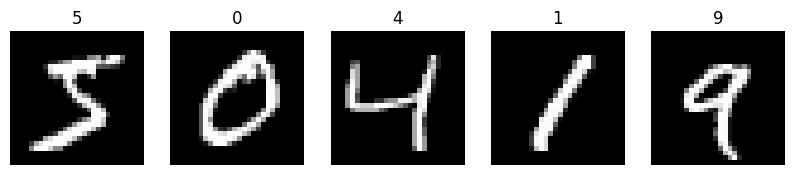

In [ ]:
plt.figure(figsize=(10, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.show()

plt.figure.. sets the size of the picture

And the loop runs 5 times
plt.subplot ... picks the panel to draw in

plt.imshow... draws image number i as agrid of grey pixels.

plt.title.. writes its label above it

In [ ]:
x_train = x_train / 255.0
x_test = x_test / 255.0
print(x_train.min(), x_train.max())

0.0 1.0


This divides every pixel by 255, so that black(0) stays that way and white(255) becomes 1

Therefore the minimum of X_train  is 0 and the maximum is 1.0

I did that because the networks learn much better from small numbers. If also for the saame reasons we scaled in those other tasks. We use plain division here instead of StandardScaler because all the pixels are already on the same scale

In [ ]:
keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

keras.utils.set_random_seed(42) fixes the random numbers so that the starting weights are the sameeach time, which makes the results repeatable it works like the random_state we have been using the the past tasks

keras.Sequential... duilds a network from a list of layers stacked in order: dta enters the first layer and each layer's output feeds the next.


model.summary() prints a table of layers and their parameters

In [ ]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

compile sets up the learning rules before training

In [ ]:
model.evaluate(x_test, y_test, verbose=0)

[2.3483457565307617, 0.10909999907016754]

Measures the untrained network on the 10,000 test images. It returns the loss and the accuracy. verbose=0 hides the progress bar.

In [ ]:
history = model.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.1)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9249 - loss: 0.2557 - val_accuracy: 0.9655 - val_loss: 0.1107
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9671 - loss: 0.1092 - val_accuracy: 0.9700 - val_loss: 0.0994
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9773 - loss: 0.0735 - val_accuracy: 0.9745 - val_loss: 0.0968
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9839 - loss: 0.0538 - val_accuracy: 0.9752 - val_loss: 0.1014
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9872 - loss: 0.0406 - val_accuracy: 0.9777 - val_loss: 0.0957
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9895 - loss: 0.0328 - val_accuracy: 0.9735 - val_loss: 0.1129
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9921 - loss: 0.0262 - val_accuracy: 0.9738 - val_loss: 0.1155
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9917 - loss: 0.0249 - 

model.fit(...) is where learning happens: forward pass, loss, backpropagation, and weight adjustments, repeated many times (the four steps from last time).

epochs=10 means 10 full passes through the training images. One pass is one epoch. Batch size=32 means the weights are adjusted after every 32 images


Epoch 1 already reaches about 92% to 96%.

The training loss keeps falling and training accuracy climbs toward 99%, because the network keeps getting better at the 54,000 images it studies.

The validation numbers stop improving after the first few epochs. Validation accuracy levels off around 97% to 98%, and the validation loss flattens or creeps up slightly.

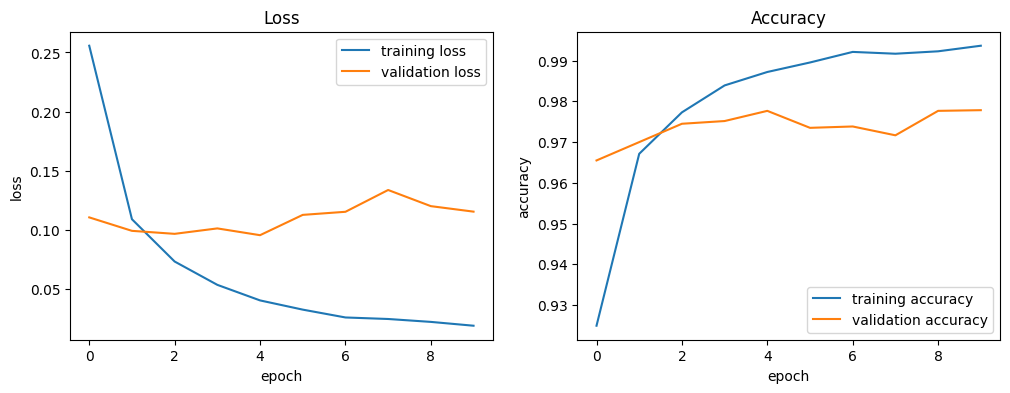

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="training accuracy")
plt.plot(history.history["val_accuracy"], label="validation accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("Accuracy")
plt.legend()

plt.show()

history.history is a dictionary holding one list per measure, with one value per epoch: "loss", "accuracy", "val_loss", and "val_accuracy". (The val_ ones come from the validation set.)
plt.subplot(1, 2, 1) and plt.subplot(1, 2, 2) pick the left and right panels of one picture.
plt.plot(list, label=...) draws a line through the values, with one point per epoch (the horizontal axis starts at 0, which is epoch 1). The labels, titles, and plt.legend() make the chart readable, and plt.show() displays it.

Loss panel: the training line should slope steadily down. The validation line should drop quickly, then flatten or tick up after about epoch 4 to 6. The place where the two lines pull apart is overfitting.
Accuracy panel: training accuracy climbs toward 0.99, and validation accuracy sits a little lower, around 0.975, with a visible gap.

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(test_loss, test_acc)

0.10088729113340378 0.9761000275611877


model.evaluate(...) scores the network on the 10,000 test images, which it has never used in any way. It returns the loss and the accuracy, which we store in two names.

In [ ]:
y_prob = model.predict(x_test)
y_pred = np.argmax(y_prob, axis=1)
print(y_prob.shape)
print(y_prob[0].round(3))
print(y_pred[:10], y_test[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
(10000, 10)
[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
[7 2 1 0 4 1 4 9 6 9] [7 2 1 0 4 1 4 9 5 9]


model.predict(x_test) returns the softmax outputs: 10 probabilities for each image.
np.argmax(y_prob, axis=1) finds, for each row, the position of the largest probability, which is the predicted digit. axis=1 means “look across the 10 values in each row”.

239


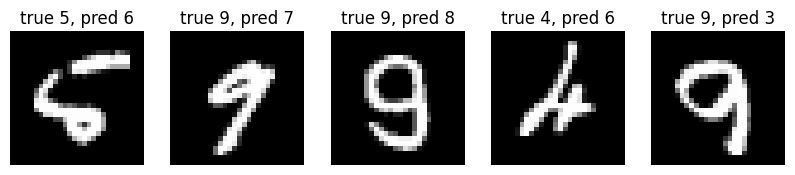

In [ ]:
wrong = np.where(y_pred != y_test)[0]
print(len(wrong))
plt.figure(figsize=(10, 3))
for i, idx in enumerate(wrong[:5]):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[idx], cmap="gray")
    plt.title(f"true {y_test[idx]}, pred {y_pred[idx]}")
    plt.axis("off")
plt.show()

This cell looks at the mistakes

y_pred != y_test compares each prediction with the truth, and np.where(...)[0] gives the positions where they differ. len(wrong) counts them.
The loop draws the first five mistakes with their true and predicted digits (enumerate gives a counter i along with each position idx).